# Dataset Explore

In [18]:
import pandas as pd 
import numpy as np

df = pd.read_csv("/home/siyam/Downloads/BostonHousing.csv")

x = df.drop('medv', axis=1)
y = df['medv']

print(df.head())

      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  


# Train Test Split

In [19]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)



# Model Train

In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


# Prediction

In [21]:
predictions = model.predict(x_test)
print(predictions[:5])

[28.99672362 36.02556534 14.81694405 25.03197915 18.76987992]


In [22]:
from sklearn.metrics import mean_squared_error, r2_score

print("MSE:", mean_squared_error(predictions, y_test))
print("R2:", r2_score(predictions, y_test))


MSE: 24.291119474973478
R2: 0.6333247469014351


# EDA

<Axes: >

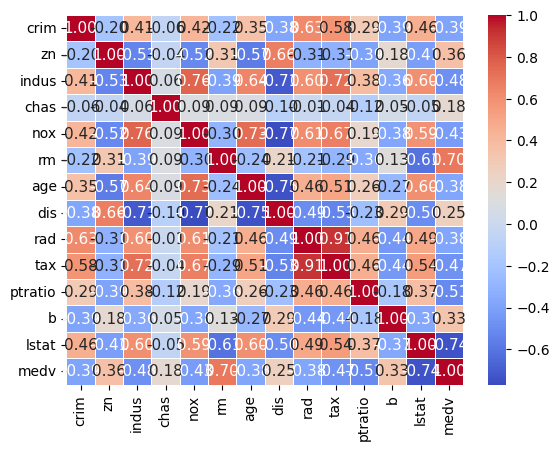

In [23]:
import seaborn as sns
sns.heatmap(
    df.corr(),
    annot=True, 
    cmap="coolwarm",  # দেখতে সুন্দর ও রিডেবল কালার
    fmt=".2f",  # দশমিকের পর মাত্র ২ ঘর দেখাবে
    annot_kws={"size": 11},  # ভেতরের সংখ্যার সাইজ পারফেক্ট করবে
    linewidths=0.5,  # বক্সগুলোর মাঝে হালকা ফাঁকা জায়গা তৈরি করবে
)

In [ ]:
corr = df.corr()
print(corr['medv'].sort_values(ascending=False))

medv       1.000000
rm         0.695360
zn         0.360445
b          0.333461
dis        0.249929
chas       0.175260
age       -0.376955
rad       -0.381626
crim      -0.388305
nox       -0.427321
tax       -0.468536
indus     -0.483725
ptratio   -0.507787
lstat     -0.737663
Name: medv, dtype: float64


In [27]:
x = df[['rm', 'lstat']]
y = df['medv']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(x_train, y_train)

predictions = model.predict(x_test)

print("MSE:", mean_squared_error(predictions, y_test))
print("R2:", r2_score(predictions, y_test))

print(model.coef_)
print(model.intercept_)



MSE: 31.243290601783627
R2: 0.421418206941802
[ 5.46509877 -0.63249856]
-3.8411770790048827


In [28]:
train_pred = model.predict(x_train)
test_pred = model.predict(x_test)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))

Train R2: 0.6501592679428922
Test R2: 0.5739577415025858
